<html>
    <div>
        <span style="float: left; font-size: 120%; font-variant: small-caps;">
            Université Paul Sabatier
        </span>
        <span style="float: right; font-size: 120%;">
            Analyse de Fourier et théorie du signal
        </span>
    </div><br><br>
    <div align="center" style="font-size: 300%; font-weight: bold;">
        TP2
    </div>
</html>

<div style="color:red; font-size: 40px;">
<b>Attention Information :</b>
</div>

<div style=color:red>
J'ai fais le TP avec la version 3.11.9 de python sur mon ordinateur personnel et j'ai du modifier 2-3 commandes dans les fichiers wavtools et imtools (jai modifié les tostring en tobytes, fromstring en frombuffer par exemple), je les ai donc mis avec mon TP si vous avez des problèmes avec ceux d'origines</div>

# Transformée de Fourier et signaux audio

Récupérer le fichier [`wavtools.py`][1] et l'enregistrer au même endroit que le notebook (clic droit sur le lien, puis "enregistrer la cible du lien sous..."). Puis exécuter le code suivant.

[1]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/wavtools.py>

In [1]:
%pylab inline
import numpy as np
import matplotlib.pyplot as plt
from imtoolsJeff import *
from wavtoolsJeff import *

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


Récupérer de la même manière les fichiers audio de travail:

- [`basson.wav`][1]
- [`bird.wav`][2]
- [`compose.wav`][3]
- [`drum.wav`][4]
- [`flute.wav`][5]
- [`garage.wav`][6]
- [`hall1.wav`][7]
- [`hall2.wav`][8]
- [`tictac.wav`][9]

Dans ce qui suit, des données audio sont représentées sous la forme d'un tableau à une dimension contenant des nombres compris entre $-1$ et $1$. Ces nombres décrivent une pression dans l'air (exprimée comme la différence par rapport à la pression au repos) au cours du temps. L'oreille perçoit ces variations de pression comme un son.

Le fichier `wavtools.py` fournit quelques fonctions utiles pour la manipulation de fichiers audio au format WAVE.

[1]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/basson.wav>
[2]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/bird.wav>
[3]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/compose.wav>
[4]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/drum.wav>
[5]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/flute.wav>
[6]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/garage.wav>
[7]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/hall1.wav>
[8]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/hall2.wav>
[9]: <http://www.math.univ-toulouse.fr/~vfeuvrie/l3mapi3/analyse%207/download/tictac.wav>

In [2]:
# Jouer un fichier WAVE

play_wave("basson.wav")

In [3]:
# Chargement d’un fichier WAVE

signal, freq = open_wave("basson.wav")

# La fonction open_wave renvoie deux choses:
#    - le signal lui-même
#    - la fréquence d'échantillonnage de ce signal
# Cette dernière permet de savoir à quelle vitesse il faut jouer les échantillons

In [4]:
# Lecture des données brutes (il faut préciser la fréquence d'échantillonnage)

signal, freq = open_wave("bird.wav")
play_wave(signal, freq)

In [5]:
# Le même code mais avec une fréquence erronnée pour la lecture

signal, freq = open_wave("bird.wav")
play_wave(signal, freq / 3)

In [6]:
sound = np.zeros(88200)
save_wave(sound, "test.wav" , 44100)

# On enregistre un fichier WAVE à 44.1 kHz, contenant 88200 échantillons valant zéro.
# On obtiendra donc un fichier avec deux secondes de silence.

## Exercice 1 – Son sinusoïdal

Dans ce qui suit, on travaille avec une fréquence d'échantillonnage des données audio de 30 kHz.

1. Générer un tableau contenant l'échantillonnage d'une fonction sinusoïdale à $440$ pulsations (périodes) par seconde pendant $3$ secondes.

In [7]:
frequence_echantillonnage = 30000  
frequence_son = 440                 
duree = 3                          
nombre_echantillons = frequence_echantillonnage * duree  


temps = np.linspace(0, duree, nombre_echantillons, endpoint=False)


signal_sinus = np.sin(2 * np.pi * frequence_son * temps)

print(f'Nombre d\'échantillons : {len(signal_sinus)}')
print(f'Valeurs entre {signal_sinus.min():.2f} et {signal_sinus.max():.2f}')

Nombre d'échantillons : 90000
Valeurs entre -1.00 et 1.00


2. Écouter le signal audio obtenu.

In [8]:
# play_wave affiche un lecteur audio dans Jupyter
play_wave(signal_sinus, frequence_echantillonnage)

3. On rappelle que la transformée de Fourier discrète d'un signal $v$ à $N$ échantillons permet d'obtenir ses coordonnées dans la base de Fourier $(f_k)_{0\leq k<N}$. Par définition, on dira que le *mode* associé à l'une de ces coordonnées est le numéro de celle-ci, c'est à dire la valeur de $k$.

    Représenter le module de la transformée de Fourier du signal en ordonnée en fonction du mode en abscisse. Pour cela, on pourra utiliser:
    
    - la fonction `fft.fft(signal)`, qui renvoie la transformée de Fourier discrète d'un signal à une dimension;
    - la fonction abs de numpy, qui renvoie le module d’un tableau de complexes. 


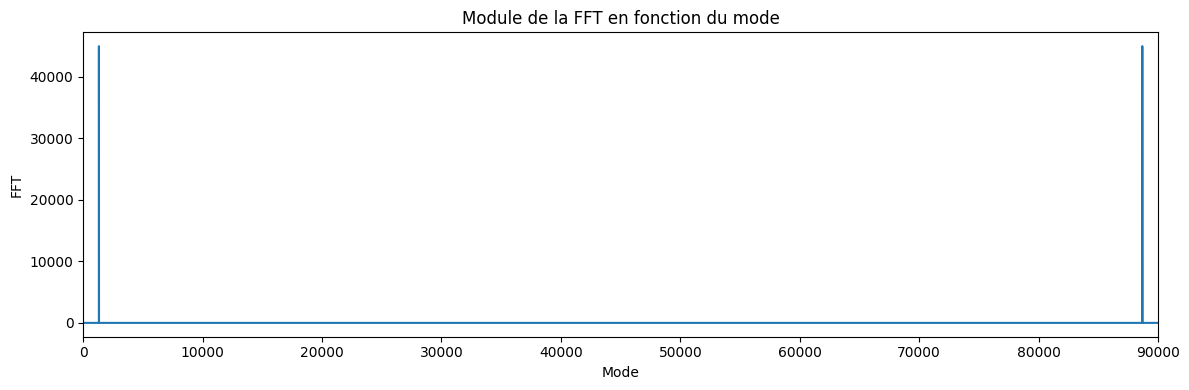

In [9]:
fft_sinus = np.fft.fft(signal_sinus)
module_fft = np.abs(fft_sinus)
modes = np.arange(len(signal_sinus))

plt.figure(figsize=(12, 4))
plt.plot(modes, module_fft)
plt.xlabel('Mode')
plt.ylabel('FFT')
plt.title('Module de la FFT en fonction du mode')
plt.xlim(0, len(signal_sinus))
plt.tight_layout()
plt.show()


4. La fonction `fft.fftfreq(N, d)` renvoie un tableau contenant les fréquences associées à la transformée de Fourier, pour un signal contenant $N$ échantillons espacés d'un intervalle $d$ ($d$ est donc l'inverse de la fréquence d'échantillonnage).

    Représenter les fréquences du signal sinusoïdal en ordonnée en fonction du mode en abscisse.

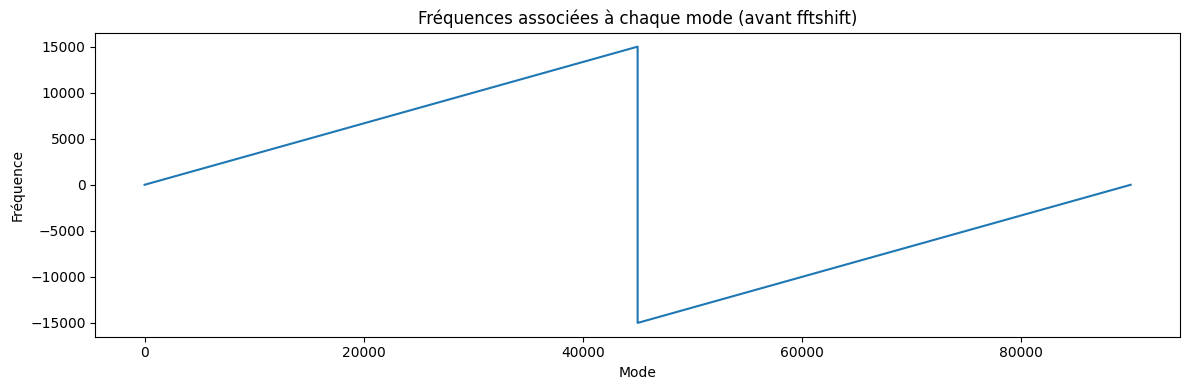

In [10]:
pas_de_temps = 1 / frequence_echantillonnage
frequences = np.fft.fftfreq(len(signal_sinus), d=pas_de_temps)

plt.figure(figsize=(12, 4))
plt.plot(modes, frequences)
plt.xlabel('Mode')
plt.ylabel('Fréquence')
plt.title('Fréquences associées à chaque mode (avant fftshift)')
plt.tight_layout()
plt.show()


5. La fonction `fft.fftshift` effectue une permutation des éléments d’un tableau. Après l'avoir testée sur le tableau renvoyé par `fft.fftfreq`, expliquer son intérêt pour la manipulation des coefficients de la transformée de Fourier.

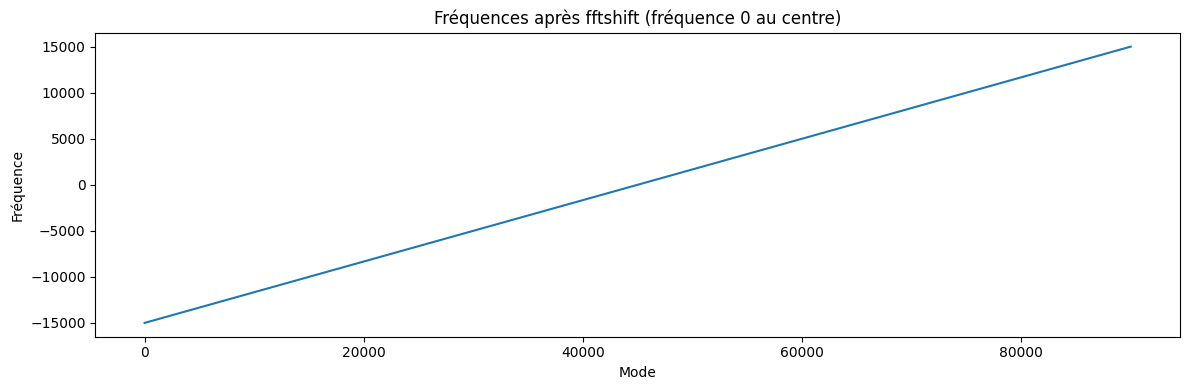

In [11]:

frequences_centrees = np.fft.fftshift(frequences)

plt.figure(figsize=(12, 4))
plt.plot(modes, frequences_centrees)
plt.xlabel('Mode')
plt.ylabel('Fréquence')
plt.title('Fréquences après fftshift (fréquence 0 au centre)')
plt.tight_layout()
plt.show()

6. Représenter le module de la FFT du signal en ordonnée en fonction des fréquences en abscisse.

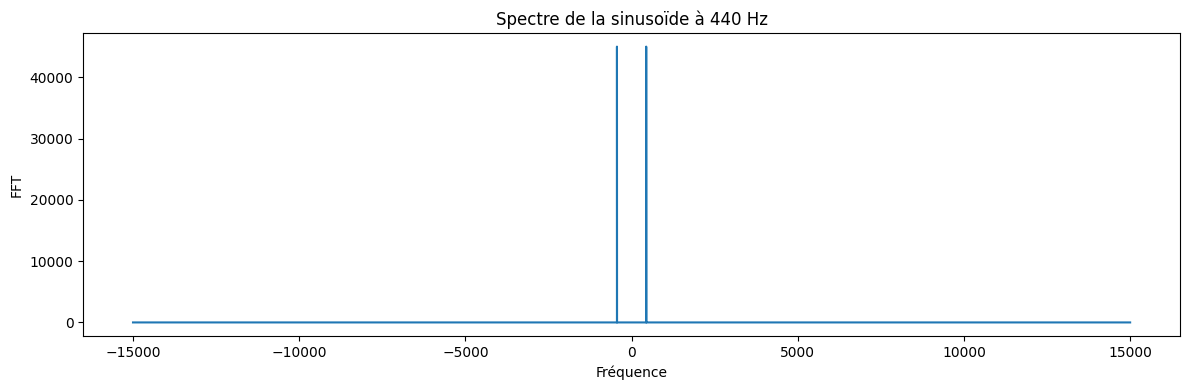

In [12]:
module_fft_centre = np.fft.fftshift(module_fft)

plt.figure(figsize=(12, 4))
plt.plot(frequences_centrees, module_fft_centre)
plt.xlabel('Fréquence')
plt.ylabel('FFT')
plt.title('Spectre de la sinusoïde à 440 Hz')
plt.tight_layout()
plt.show()


7. Même question en remplaçant le signal sinusoïdal par un signal périodique triangulaire de même fréquence (on pourra remplacer l'expression de la forme `sin(x)` par `2 * arcsin(sin(x)) / pi`).

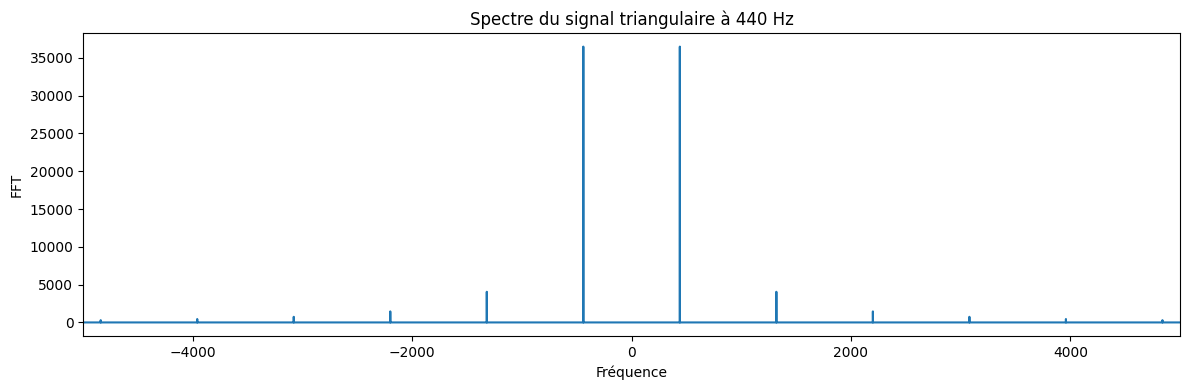

In [13]:
argument = 2 * np.pi * frequence_son * temps
signal_triangulaire = 2 * np.arcsin(np.sin(argument)) / np.pi


fft_triangulaire = np.fft.fft(signal_triangulaire)
module_fft_tri = np.fft.fftshift(np.abs(fft_triangulaire))

plt.figure(figsize=(12, 4))
plt.plot(frequences_centrees, module_fft_tri)
plt.xlabel('Fréquence')
plt.ylabel('FFT')
plt.title('Spectre du signal triangulaire à 440 Hz')
plt.xlim(-5000, 5000)
plt.tight_layout()
plt.show()


8. Même question en remplaçant le signal sinusoïdal par un signal périodique carré de même fréquence (on pourra remplacer l'expression de la forme `sin(x)` par `sign(sin(x))`).

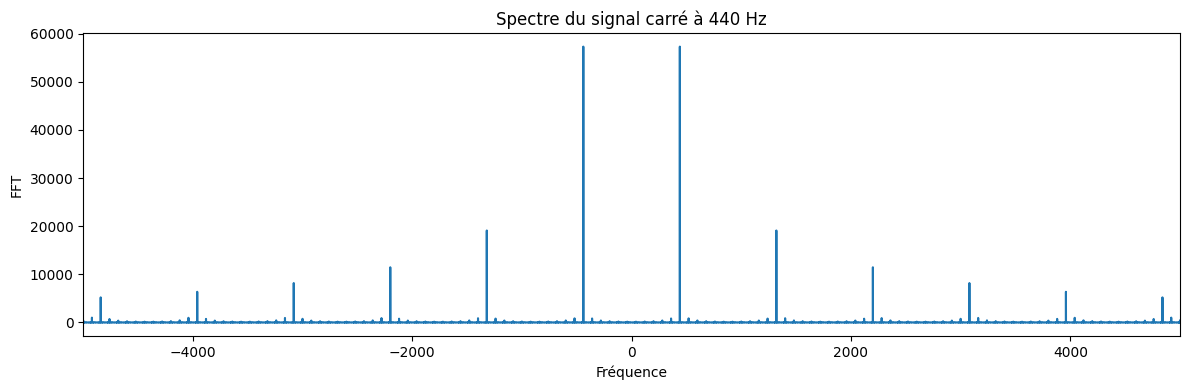

In [14]:
signal_carre = np.sign(np.sin(argument))

fft_carre = np.fft.fft(signal_carre)
module_fft_carre = np.fft.fftshift(np.abs(fft_carre))

plt.figure(figsize=(12, 4))
plt.plot(frequences_centrees, module_fft_carre)
plt.xlabel('Fréquence')
plt.ylabel('FFT')
plt.title('Spectre du signal carré à 440 Hz')
plt.xlim(-5000, 5000)
plt.tight_layout()
plt.show()


9. Décrire qualitativement les résultats obtenus.

<div style=color:blue>
<u>Sinusoïde:</u> spectre avec exactement deux pics en ±440 Hz, amplitude nulle partout ailleurs. C'est le signal le plus « pur » spectralement.

<u>Signal triangulaire:</u> en plus du fondamental à 440 Hz, il contient des harmoniques impaires(3×440, 5×440, …) dont l'amplitude décroît en 1/k² (très vite). Son spectre est discret mais plus riche.

<u>Signal carré:</u> même structure d'harmoniques impaires, mais l'amplitude décroît en 1/k (plus lentement). Les discontinuités du signal carré (sauts brutaux) nécessitent beaucoup plus de fréquences pour être représentées — d'où un spectre plus étalé.</div>

## Exercice 2 – Deux sons sinusoïdaux

1. Sur le modèle de l'exercice précédent, générer un fichier audio de deux secondes, contenant :

    - un signal sinusoïdal de fréquence 440Hz pendant la première seconde ;
    - un signal sinusoïdal de fréquence 600Hz pendant la deuxième seconde.

In [15]:
frequence_echantillonnage = 30000
duree_partie = 1  
nb_echantillons_partie = frequence_echantillonnage * duree_partie  

temps_une_seconde = np.linspace(0, duree_partie, nb_echantillons_partie, endpoint=False)


frequence_1 = 440
signal_premiere_seconde = np.sin(2 * np.pi * frequence_1 * temps_une_seconde)

frequence_2 = 600
signal_deuxieme_seconde = np.sin(2 * np.pi * frequence_2 * temps_une_seconde)

signal_deux_tons = np.concatenate([signal_premiere_seconde, signal_deuxieme_seconde])

print(f'Longueur totale : {len(signal_deux_tons)} échantillons = {len(signal_deux_tons)/frequence_echantillonnage} secondes')
play_wave(signal_deux_tons, frequence_echantillonnage)

Longueur totale : 60000 échantillons = 2.0 secondes


2. Représenter le module de la FFT du signal en fonction des fréquences, en se limitant aux fréquences comprises entre -1000 et +1000 Hz.

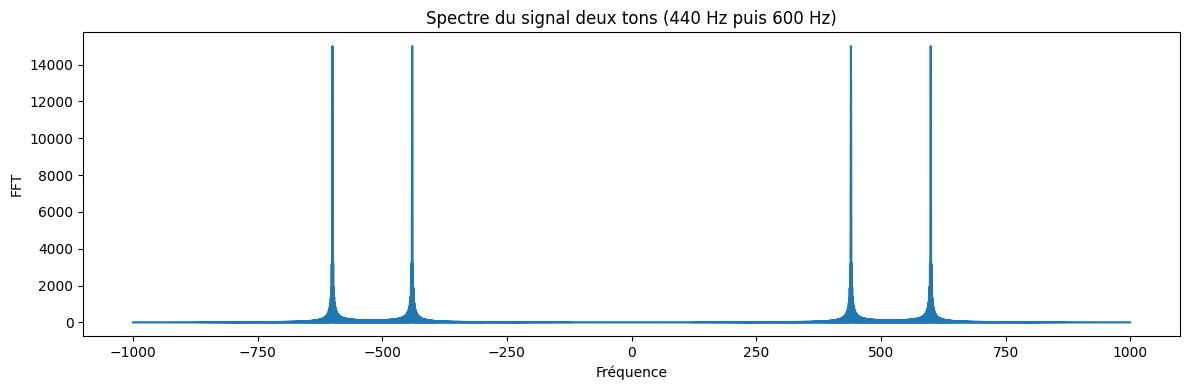

In [16]:
fft_deux_tons = np.fft.fft(signal_deux_tons)
module_fft_deux_tons = np.fft.fftshift(np.abs(fft_deux_tons))

nb_total = len(signal_deux_tons)
frequences_deux_tons = np.fft.fftshift(
    np.fft.fftfreq(nb_total, d=1/frequence_echantillonnage)
)

masque = (frequences_deux_tons >= -1000) & (frequences_deux_tons <= 1000)

plt.figure(figsize=(12, 4))
plt.plot(frequences_deux_tons[masque], module_fft_deux_tons[masque])
plt.xlabel('Fréquence')
plt.ylabel('FFT')
plt.title('Spectre du signal deux tons (440 Hz puis 600 Hz)')
plt.tight_layout()
plt.show()

3. Décrire qualitativement les résultats obtenus.

<div style=color:blue>On observe quatre pics dans le spectre (deux fréquences positives + leurs symétriques négatifs) : à ±440 Hz et ±600 Hz. Même si les deux sons ne sont pas joués simultanément, la FFT les détecte car elle analyse la totalité du signal. Les pics ne sont pas infiniment fins (comme pour un signal infini) mais légèrement élargis — c'est l'effet de la durée finie du signal (fenêtrage).</div>

## Exercice 3 – Identifier des notes de musique

Voici un tableau contenant les fréquences de quelques notes de musique.

| do | ré | mi | fa | sol | la | si | do | ré |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 261.6 Hz | 293.7 Hz | 329.6 Hz | 349.2 Hz | 392.0 Hz | 440 Hz | 493.9 Hz | 523.2 Hz | 587.3 Hz |

1. Charger les trois fichiers fournis : `flute.wav`, `basson.wav` et `compose.wav`, puis représenter le module de leur FFT en fonction des fréquences.

Flûte   : 287522 échantillons  48000.0 Hz
Basson  : 344670 échantillons  48000.0 Hz
Composé : 277016 échantillons  48000.0 Hz


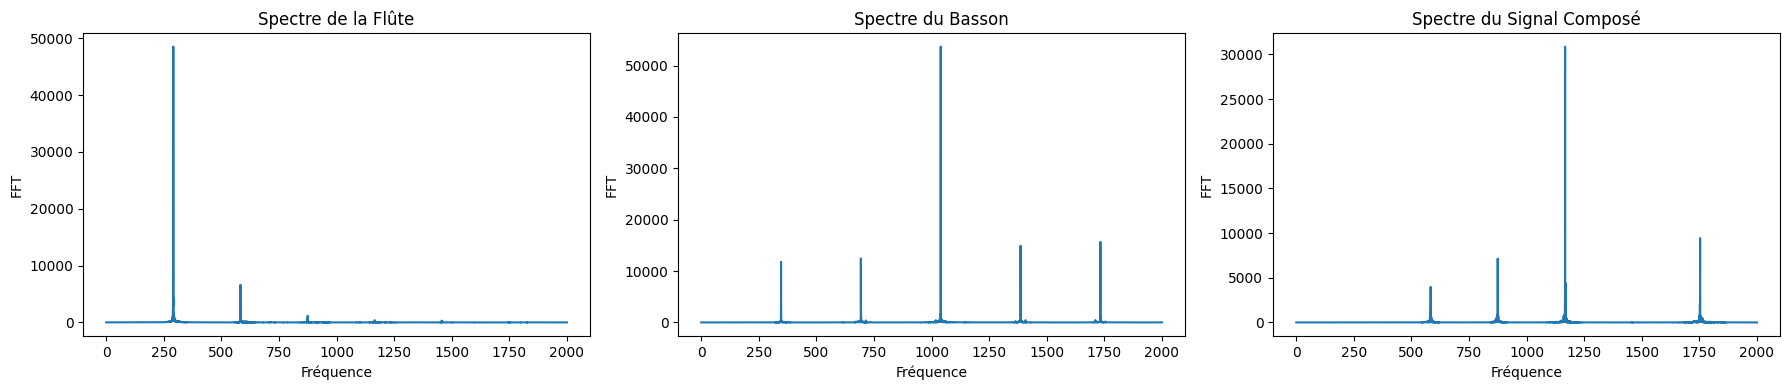

Flûte


In [17]:
signal_flute, freq_flute = open_wave('flute.wav')
signal_basson, freq_basson = open_wave('basson.wav')
signal_compose, freq_compose = open_wave('compose.wav')

print(f'Flûte   : {len(signal_flute)} échantillons  {freq_flute} Hz')
print(f'Basson  : {len(signal_basson)} échantillons  {freq_basson} Hz')
print(f'Composé : {len(signal_compose)} échantillons  {freq_compose} Hz')

def afficher_spectre(signal, freq_ech, titre, xlim=2000):
    n = len(signal)
    fft_signal = np.fft.fft(signal)
    module = np.fft.fftshift(np.abs(fft_signal))
    frequences = np.fft.fftshift(np.fft.fftfreq(n, d=1/freq_ech))
    
    masque = (frequences >= 0) & (frequences <= xlim)
    plt.plot(frequences[masque], module[masque])
    plt.xlabel('Fréquence')
    plt.ylabel('FFT')
    plt.title(titre)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

plt.sca(axes[0])
afficher_spectre(signal_flute, freq_flute, 'Spectre de la Flûte')

plt.sca(axes[1])
afficher_spectre(signal_basson, freq_basson, 'Spectre du Basson')

plt.sca(axes[2])
afficher_spectre(signal_compose, freq_compose, 'Spectre du Signal Composé')

plt.tight_layout()
plt.show()

print('Flûte')
play_wave(signal_flute, freq_flute)

In [18]:
print('Basson')
play_wave(signal_basson, freq_basson)

Basson


In [19]:
print('Composé')
play_wave(signal_compose, freq_compose)

Composé


2. Essayer d'identifier graphiquement la fréquence fondamentale (la plus petite fréquence non nulle) de chacun des fichiers, et en déduire la note perçue par l'oreille.

In [20]:
notes = {
    'do':  261.6,
    'ré':  293.7,
    'mi':  329.6,
    'fa':  349.2,
    'sol': 392.0,
    'la':  440.0,
    'si':  493.9,
    'do2': 523.2,
    'ré2': 587.3,
}

def identifier_note(frequence_fondamentale):
    note_proche = sorted(notes.keys(), key=lambda n: abs(notes[n] - frequence_fondamentale))[0]
    return note_proche, notes[note_proche]

def trouver_fondamentale(signal, freq_ech, seuil_relatif=0.05):
    n = len(signal)
    fft_signal = np.abs(np.fft.fft(signal))
    frequences = np.fft.fftfreq(n, d=1/freq_ech)
    
    masque = (frequences > 50) & (frequences < 2000)
    freq_pos = frequences[masque]
    module_pos = fft_signal[masque]
    
    idx_max = np.argmax(module_pos)
    freq_fondamentale = freq_pos[idx_max]
    return freq_fondamentale

for nom, (signal, freq_ech) in [
    ('Flûte',   (signal_flute,   freq_flute)),
    ('Basson',  (signal_basson,  freq_basson)),
    ('Composé', (signal_compose, freq_compose)),
]:
    freq_fond = trouver_fondamentale(signal, freq_ech)
    note, freq_note = identifier_note(freq_fond)
    print(f'{nom:10s} → fréquence fondamentale ≈ {freq_fond:.1f} Hz  →  note : {note} ({freq_note} Hz)')

Flûte      → fréquence fondamentale ≈ 291.3 Hz  →  note : ré (293.7 Hz)
Basson     → fréquence fondamentale ≈ 1039.7 Hz  →  note : ré2 (587.3 Hz)
Composé    → fréquence fondamentale ≈ 1167.2 Hz  →  note : ré2 (587.3 Hz)


3. Décrire qualitativement les résultats obtenus.

<div style=color:blue>
Chaque instrument a un timbre différent : même si deux instruments jouent la même note (même fréquence fondamentale), leurs spectres sont différents car ils n'ont pas les mêmes harmoniques ni les mêmes amplitudes relatives. C'est ce qui permet à l'oreille de distinguer une flûte d'un basson.

La flûte a un spectre relativement pur (peu d'harmoniques prononcées), tandis que le basson a un spectre plus riche avec de nombreuses harmoniques de grande amplitude — ce qui lui donne ce son grave et complexe.

Le fichier compose.wav contient plusieurs notes, d'où un spectre avec plusieurs fréquences fondamentales visibles.</div>

# Transformée de Fourier à deux dimensions

## Exercice 4 – Visualiser le module d'une FFT à deux dimensions

1.  La fonction `fft.fft2` permet de calculer la transformée de Fourier discrète d'un signal à deux dimensions. Elle renvoie un tableau de complexes à deux dimensions et de même taille.

    Calculer la transformée de Fourier $\hat u$ de l'image `lena.png` et afficher son module $\vert\hat u\vert$ (on pourra utiliser la fonction `abs`, qui renvoie le module d'un tableau de complexes).

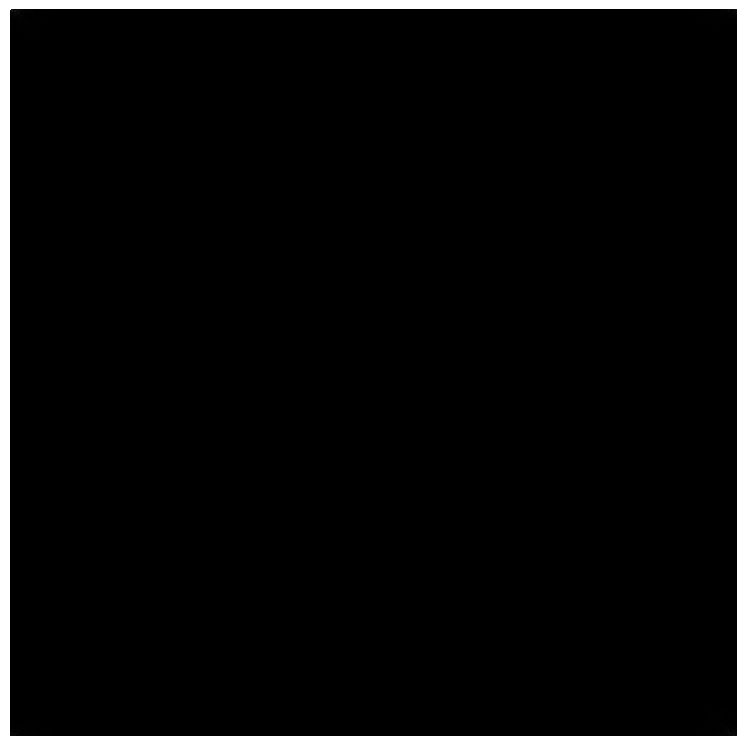

In [21]:
image = open_image("lena.png")
image = (image - image.min()) / (image.max() - image.min()) * 255

fft2d_image = np.fft.fft2(image)
module_fft2d = np.abs(fft2d_image)
display_image(module_fft2d)


2.  L'affichage tel quel du module n'est pas très lisible. Essayer de l'afficher à nouveau avec `display_image` et en utilisant le paramètre additionnel `vmax=10000`

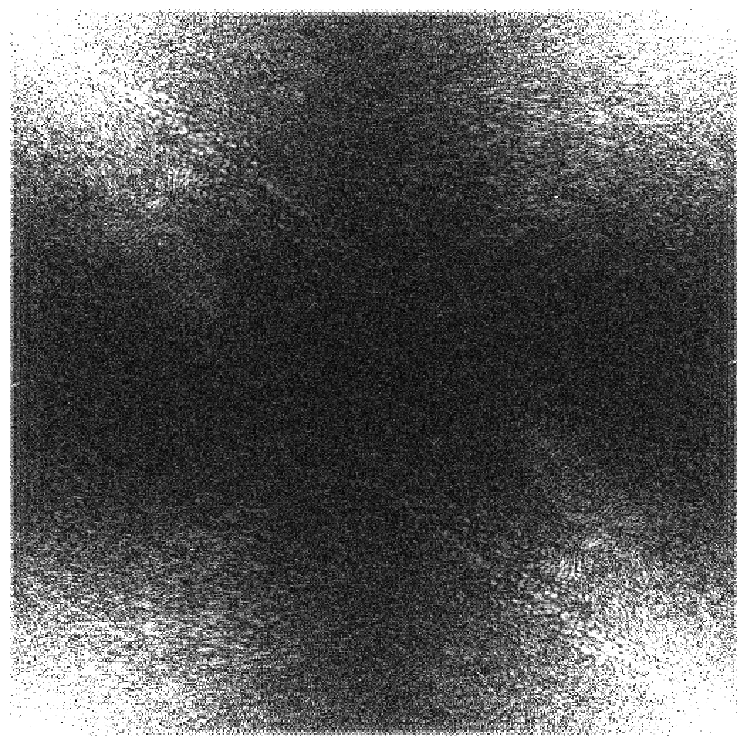

In [22]:
display_image(module_fft2d, vmax=10000)

3.  Avec la fonction `fftshift`, effectuer un changement de repère de manière à ce que l'origine soit placé au centre du dessin et afficher à nouveau $\vert\hat u\vert$ avec `vmax=10000`.

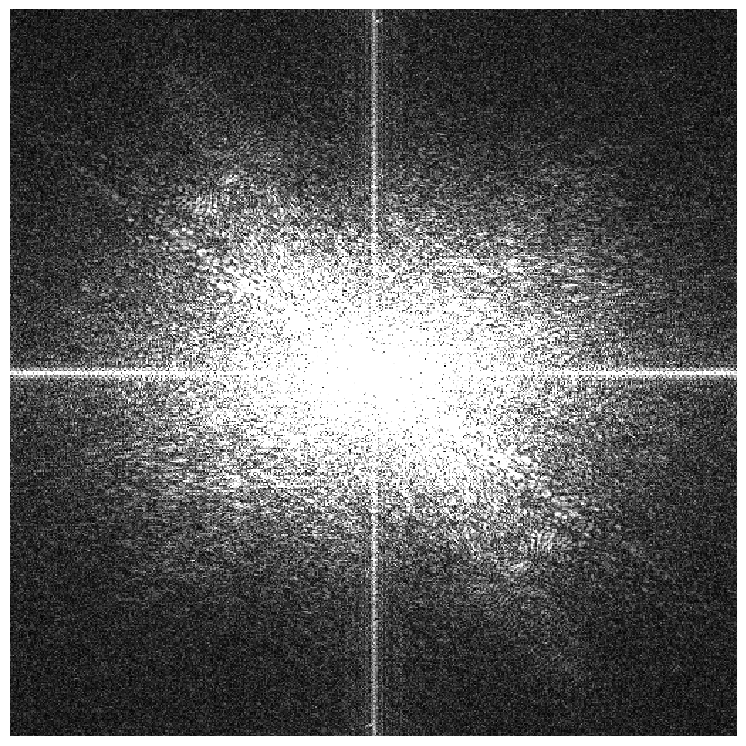

In [23]:
module_fft2d_centre = np.fft.fftshift(module_fft2d)
display_image(module_fft2d_centre, vmax=10000)

4.  Essayer d'afficher $\vert\hat u\vert$ sans utiliser `vmax=10000`, mais avec une échelle logarithmique de niveaux de gris. On pourra utiliser la formule:

    $$\large\log(1+\vert\hat u\vert)$$

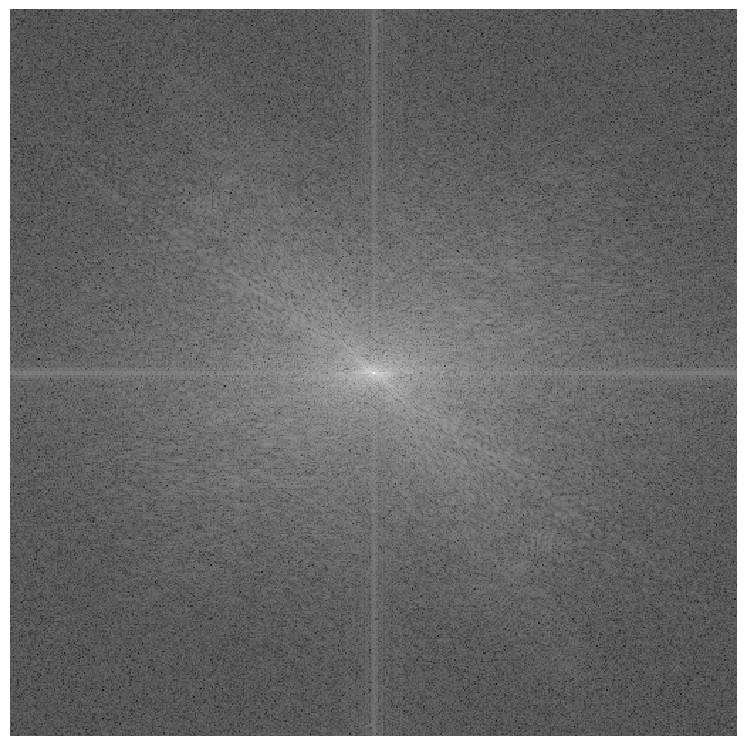

In [24]:
module_fft2d_log = np.log(1 + module_fft2d_centre)
display_image(module_fft2d_log)

5. Décrire qualitativement les résultats obtenus.

<div style=color:blue> 
<u>Sans traitement:</u> Ce résultat est dû à la dynamique extrême des coefficients. Le coefficient de fréquence nulle (la valeur moyenne de l'image) est plusieurs ordres de grandeur plus élevé que les autres. Sans traitement d'affichage, les détails fréquentiels sont écrasés et invisibles à l'œil nu.<br><br>
<u>Avec vmax=10000:</u> En fixant un seuil de saturation manuel (vmax), on "sacrifie" la précision des basses fréquences (les plus énergétiques) pour faire ressortir les moyennes fréquences. Cependant, la structure globale est difficile à interpréter car le spectre est périodisé (les basses fréquences sont aux extrémités du tableau)<br><br>
<u>Avec fftshift:</u> Ce traitement ne modifie pas les valeurs, mais réorganise les données de manière intuitive. L'origine (0,0) est placée au centre, permettant de visualiser la symétrie centrale du spectre. On observe que l'énergie se concentre selon deux axes (vertical et horizontal), ce qui correspond aux structures géométriques dominantes de l'image.<br><br>
<u>Avec log(1 + |FFT|):</u>Le logarithme agit comme un compresseur de dynamique. Il permet de représenter sur une même image des valeurs très grandes (le "fond" de l'image) et des valeurs très petites (les détails fins et le bruit). C'est la seule méthode qui permet une analyse exhaustive du contenu fréquentiel du signal sans perdre d'information par saturation.<br></div>

# Exercice 5 – Interpréter le module d'une FFT à deux dimensions

Les questions qui suivent peuvent être réalisées avec des boucles `for`. Toutefois, Python offre de nombreuses façons de « vectoriser » l'effet d'une ou plusieurs boucles, notamment avec la fonction `meshgrid` qui permet de remplacer deux boucles imbriquées.

L'avantage est une exécution plus rapide et une lisibilité accrue du code. Dorénavant, lorsque c'est possible, on préférera l'utiliser plutôt qu'écrire des boucles.

L'exemple qui suit présente l'équivalence entre un code itératif classique basé sur des boucles pour remplir un tableau à deux dimensions, et sa version vectorisée basée sur `meshgrid`. On considère l'image digitale $(u_{m,n})_{\substack{0\leq m<20\\0\leq n<30}}$ de taille $20\times 30$ définie par

$$\large u_{m,n}=(-1)^{m+n}.$$

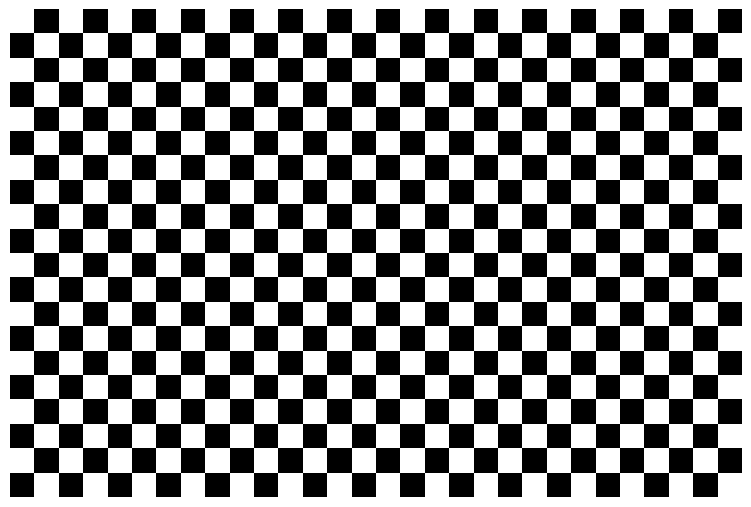

In [25]:
# Remplissage d'un damier avec des boucles

u = np.zeros((20, 30))
for m in range(20):
    for n in range(30):
        u[m, n] = (-1) ** (m + n)
display_image(u)

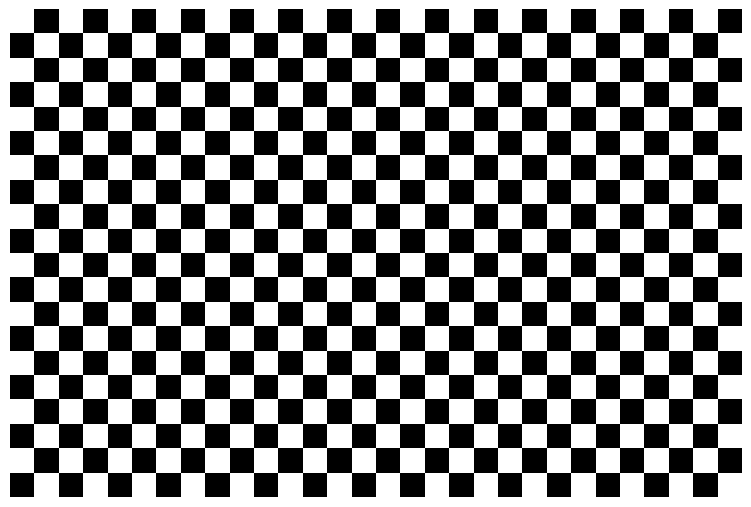

In [26]:
# Remplissage du même damier avec meshgrid

u = np.zeros((20, 30))
m, n = np.meshgrid(range(20), range(30))
u[m, n] = (-1) ** (m + n)
display_image(u)

1.  Dans ce qui suit on fixe $N=32$. Pour commencer on prend $f=1$ et on considère l'image carrée $(A_{m,n})_{\substack{0\leq m<N\\0\leq n<N}}$ définie par
    
    $$A_{m,n}=\large\cos\left(\frac{2\pi fm}{N}\right).$$
    
    Générer l'image $A$ sous forme d'un tableau et l'afficher avec `display_image`.

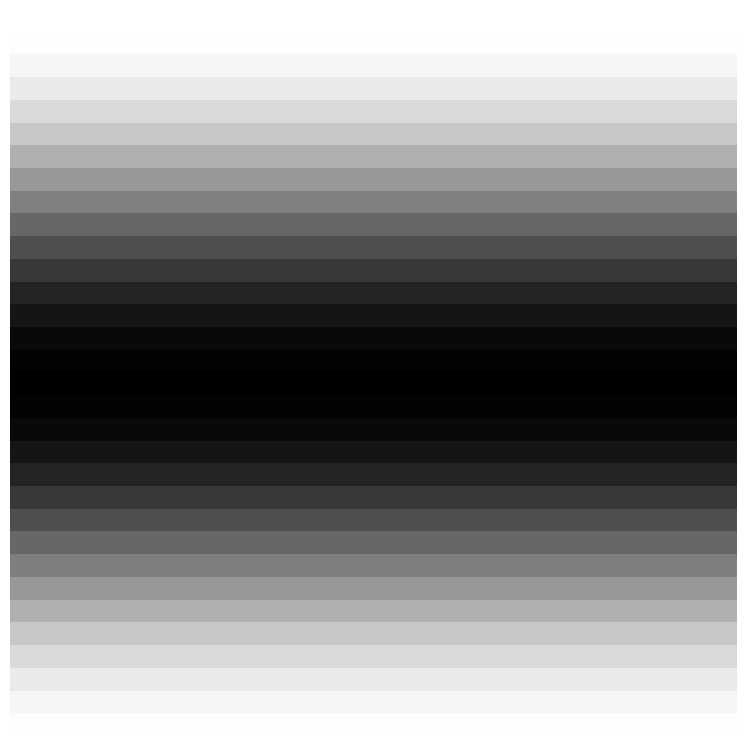

In [27]:
N = 32
n_grille, m_grille = np.meshgrid(np.arange(N), np.arange(N))
f = 1
image_A = np.cos(2 * np.pi * f * m_grille / N)
display_image(image_A)


2.  Comme on peut le constater, $A$ n'est pas en l'état une image digitale au format standard, puisqu'elle prend ses valeurs entre $-1$ et $1$ au lieu de $0$ et $255$. Python, après avoir calculé le minimum et le maximum des valeurs de l'image, se charge d'appliquer automatiquement avant l'affichage un changement de contraste affine qui envoie la valeur minimale de l'image sur $0$ (noir) et la valeur maximale sur $255$ (blanc).

    Construire un deuxième tableau $B$ en effectuant vous-même ce changement de contraste. On l'affichera de la manière suivante:
    
    ```python
display_image(B, vmin = 0, vmax = 255)
    ```
    
    de manière à inhiber le changement de contraste automatique de Python. Vérifier que l'affichage obtenu est le même que précédemment.

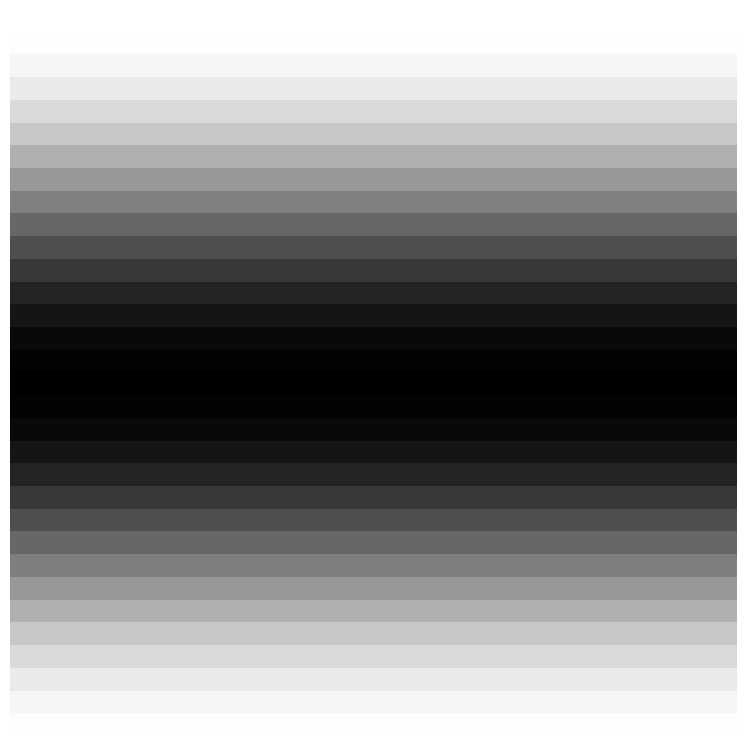

In [28]:
valeur_min = image_A.min()  
valeur_max = image_A.max()  

image_B = (image_A - valeur_min) / (valeur_max - valeur_min) * 255

display_image(image_B, vmin=0, vmax=255)

3.  Calculer et afficher le module de la fft de $A$, en plaçant l'origine au centre.

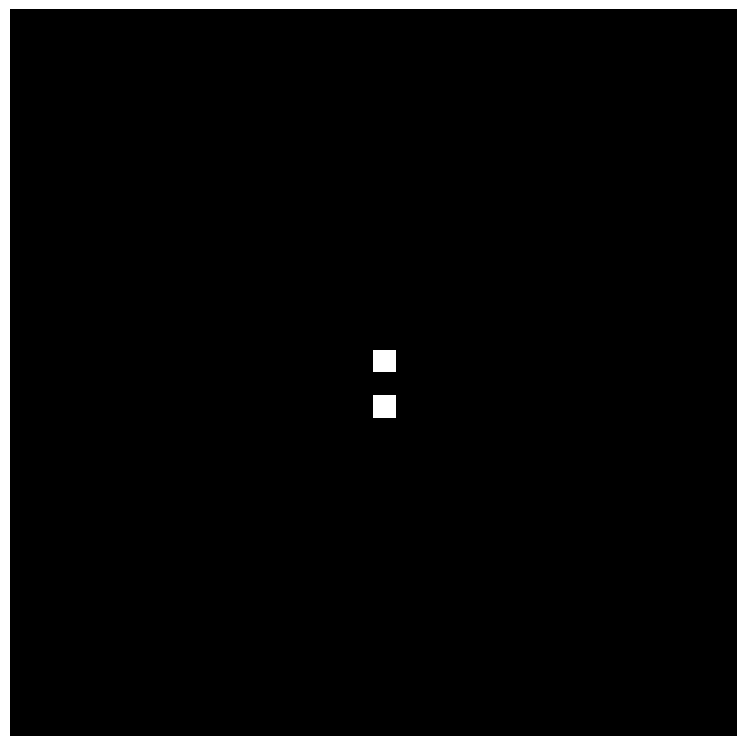

In [29]:
fft2 = np.fft.fft2(image_A)
module = np.fft.fftshift(np.abs(fft2))
display_image(np.log(1 + module))

4.  Même question pour l'image $B$.

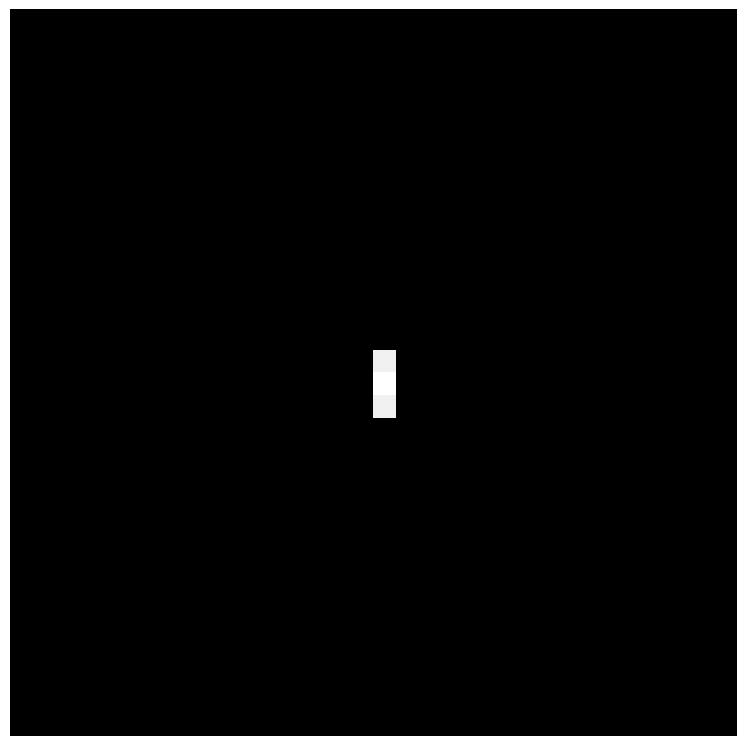

In [30]:
fft2 = np.fft.fft2(image_B)
module = np.fft.fftshift(np.abs(fft2))
display_image(np.log(1 + module))

5.  Refaire les questions précédentes avec $f=8$.

Image A et Image B avec le paramètre f = 8


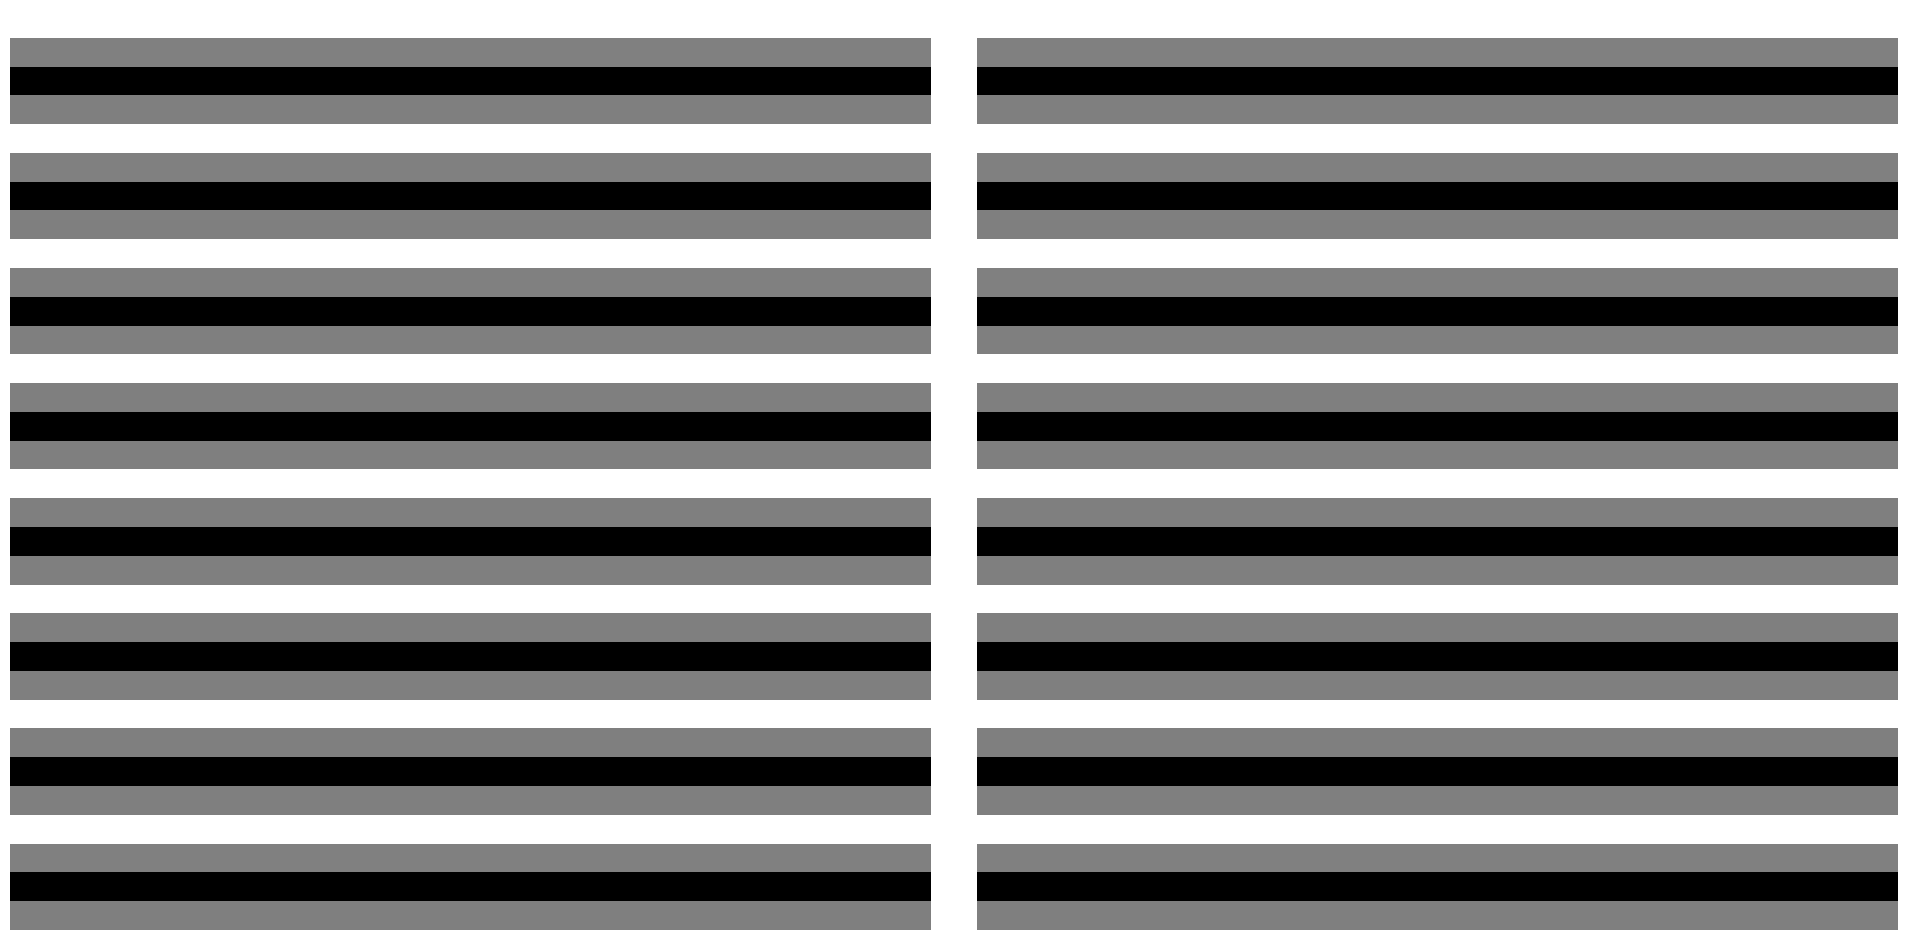

In [31]:
f = 8
image_A8 = np.cos(2 * np.pi * f * m_grille / N)
valeur_min = image_A8.min()  
valeur_max = image_A8.max()  

image_B8 = (image_A8 - valeur_min) / (valeur_max - valeur_min) * 255
fft2 = np.fft.fft2(image_A8)
module_A8 = np.fft.fftshift(np.abs(fft2))

fft2 = np.fft.fft2(image_B8)
module_B8 = np.fft.fftshift(np.abs(fft2))

print("Image A et Image B avec le paramètre f = 8")
display_images([image_A8, image_B8])

Module des fft de A et B avec f = 8


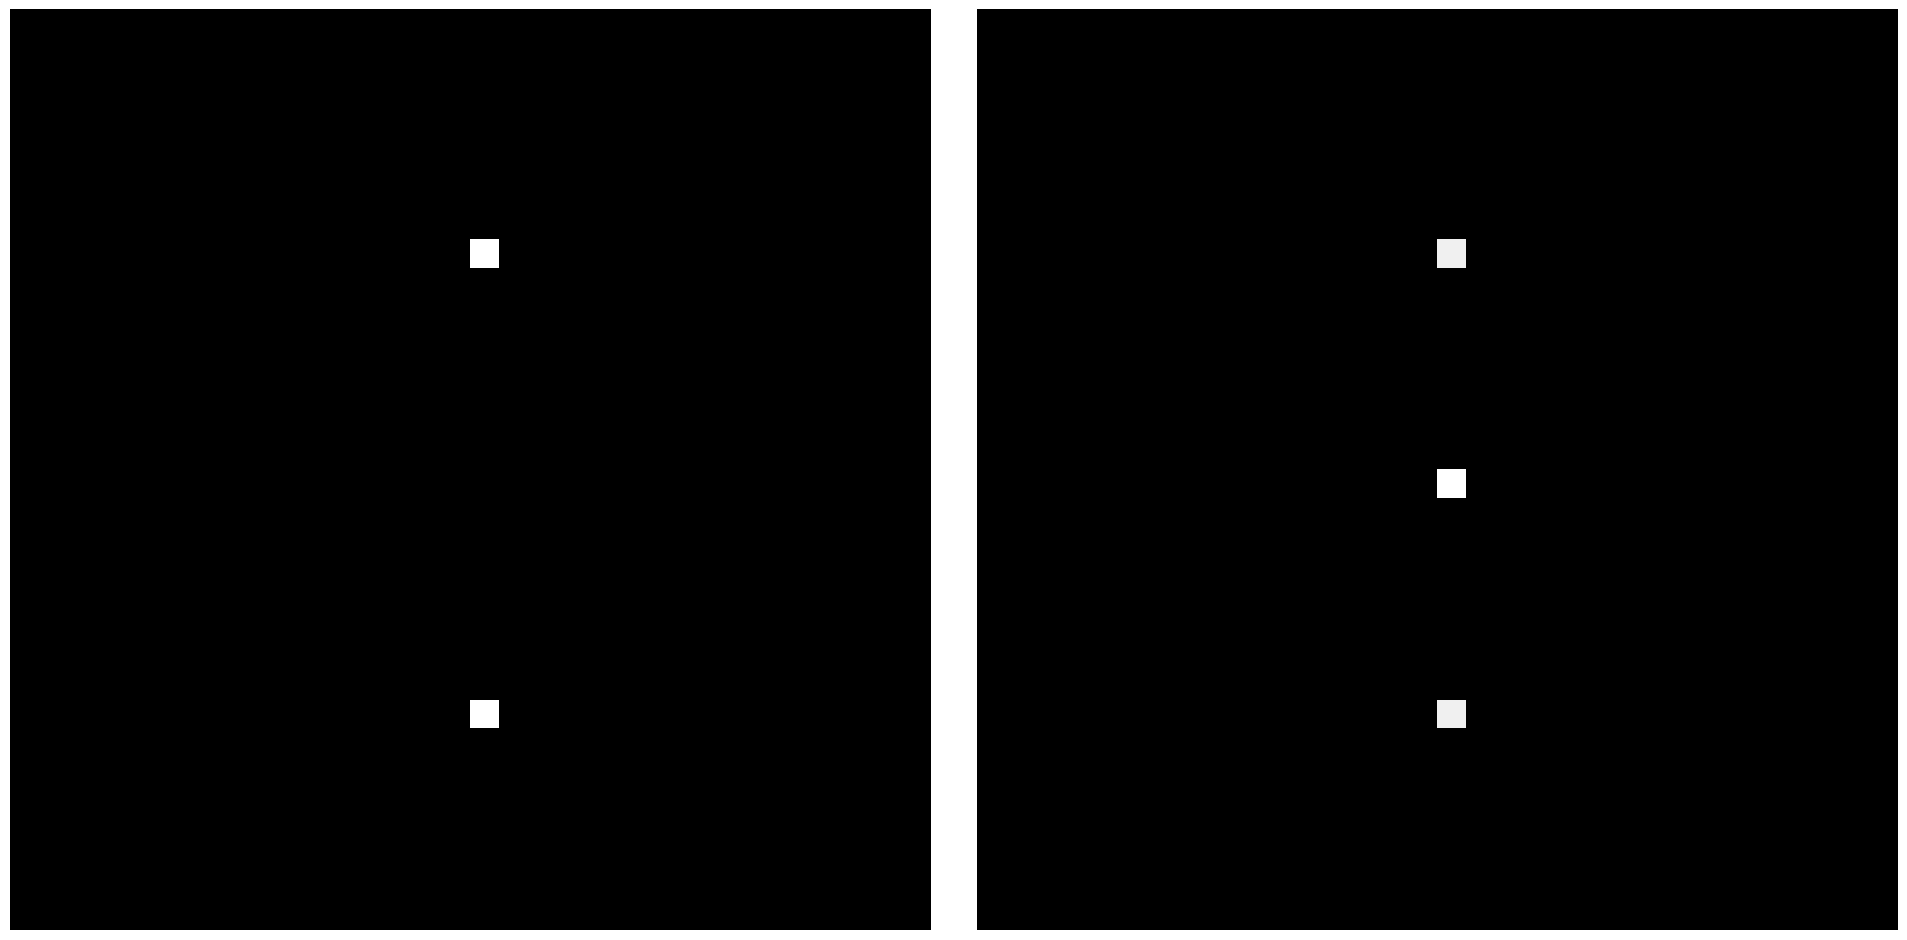

In [32]:
print("Module des fft de A et B avec f = 8")
display_images([np.log(1 + module_A8), np.log(1 + module_B8)])

6.  Créer l'image $C$ définie par

    $$\large C_{m,n}=\cos\left(\frac{2\pi(mf_1+nf_2)}{N}\right)$$
    
    en prenant $f_1=4$ et $f_2=8$. Reproduire les questions précédentes avec $C$.

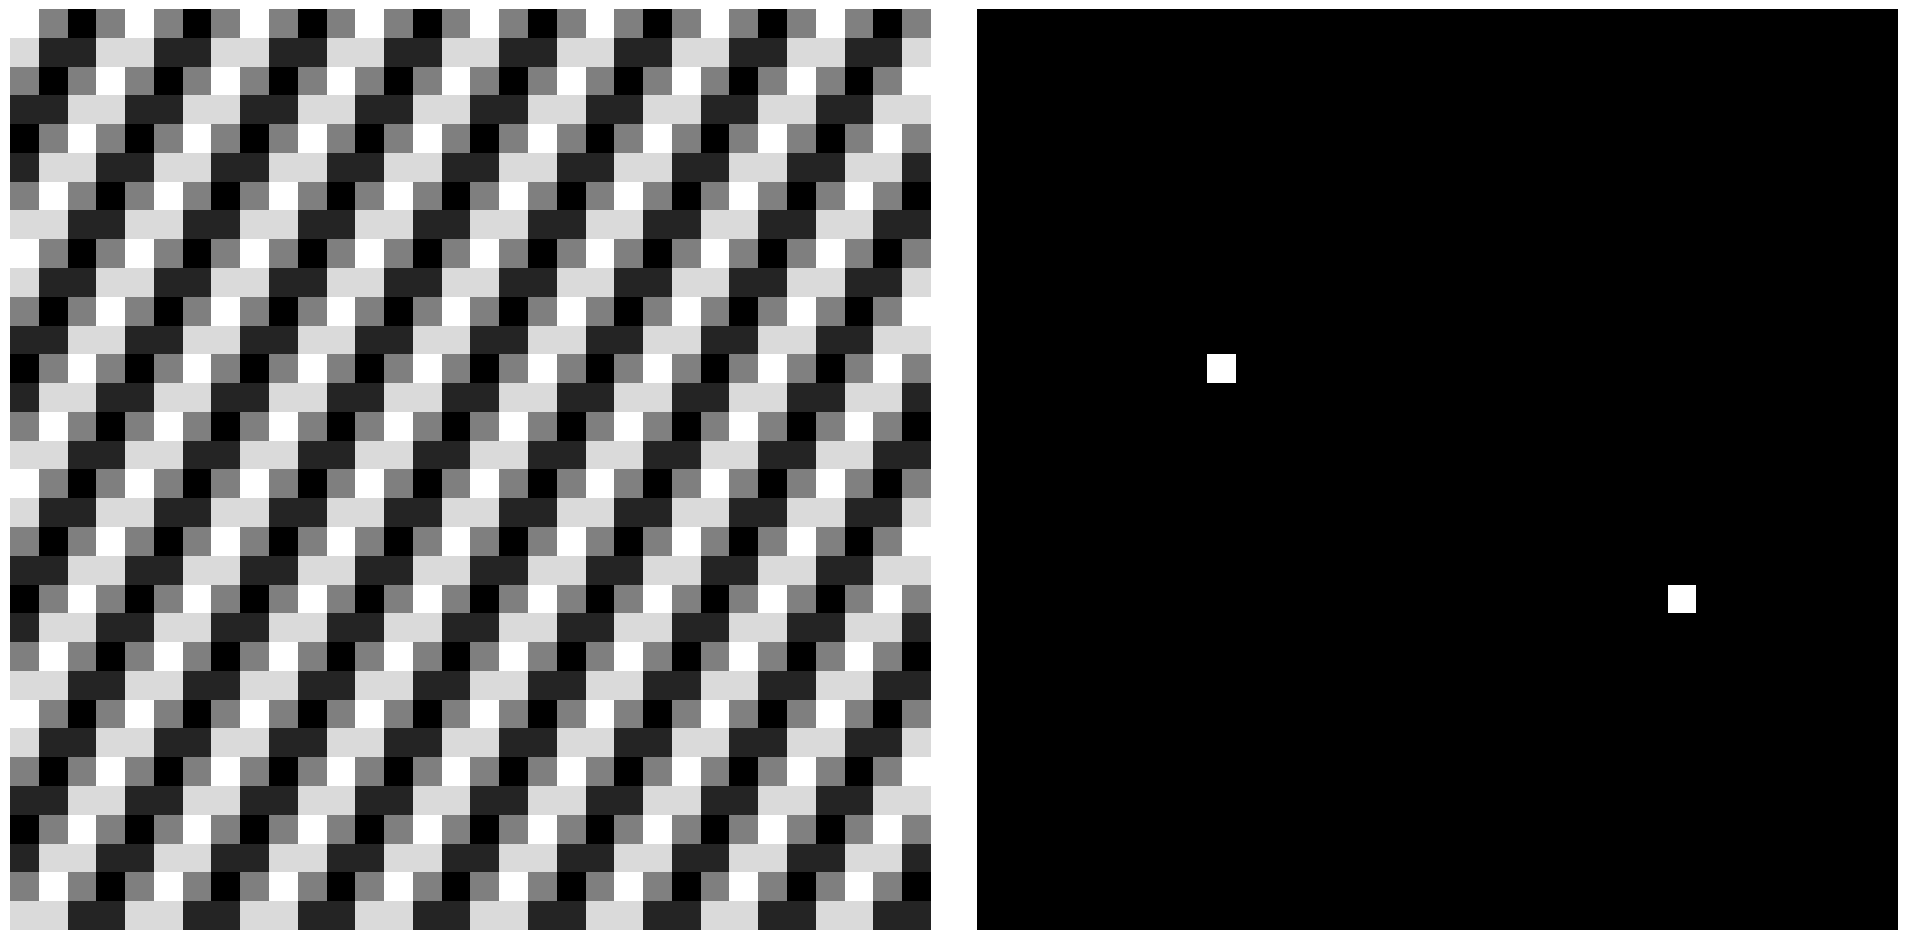

In [33]:
f1, f2 = 4, 8

image_C = np.cos((2 * np.pi * (m_grille * f1 + n_grille * f2)) / N)
fftC = np.fft.fft2(image_C)
module_C = np.fft.fftshift(np.abs(fftC))
display_images([image_C, np.log(1 + module_C)])


7.  Décrire qualitativement les résultats obtenus.

<div style=color:blue>
<u>Image A (f=1):</u> bandes horizontales à basse fréquence → deux pics proches du centre dans le spectre (sur l'axe vertical des fréquences spatiales selon m).<br><br>
<u>Image A (f=8):</u> bandes horizontales à haute fréquence → les pics s'éloignent du centre.<br><br>
<u>Image B (f=1):</u> Le spectre de Fourier affiche deux carrés blancs collés au centre (après fftshift). Cela correspond aux très basses fréquences. Le signal varie très lentement dans l'espace, donc l'énergie est concentrée presque exclusivement autour de la fréquence nulle (composante continue).<br><br>
<u>Image B (f= 8):</u>Le spectre affiche trois points (ou carrés) blancs espacés.Le point central représente toujours la moyenne de l'image.Les deux points latéraux sont les pics de Dirac situés aux fréquences +f et -f. L'espacement par rapport au centre est directement proportionnel à la fréquence $f=8$. Plus $f$ augmente, plus ces points s'éloignent du centre.<br><br>
<u>Comparaison A et B pour f = 8:</u> Cela s'explique par le fait que le module de la TF est insensible à la phase (le décalage) du signal. Que la sinusoïde commence par un pic blanc ou un creux noir, l'énergie fréquentielle reste la même. Seule la phase (que nous n'affichons pas ici) permettrait de les distinguer.<br><br>
<u>Image C:</u> le motif est oblique (dépend de m et n) → les pics apparaissent en dehors des axes, à la position (f1, f2) dans le plan fréquentiel.<br><br>
</div>

8.  Répéter les mêmes questions pour l'image $D$ définie par

    $$\large D_{m,n}=sign\left(\cos\left(\frac{2\pi fm}{N}\right)\right).$$
    
avec $f=2$.

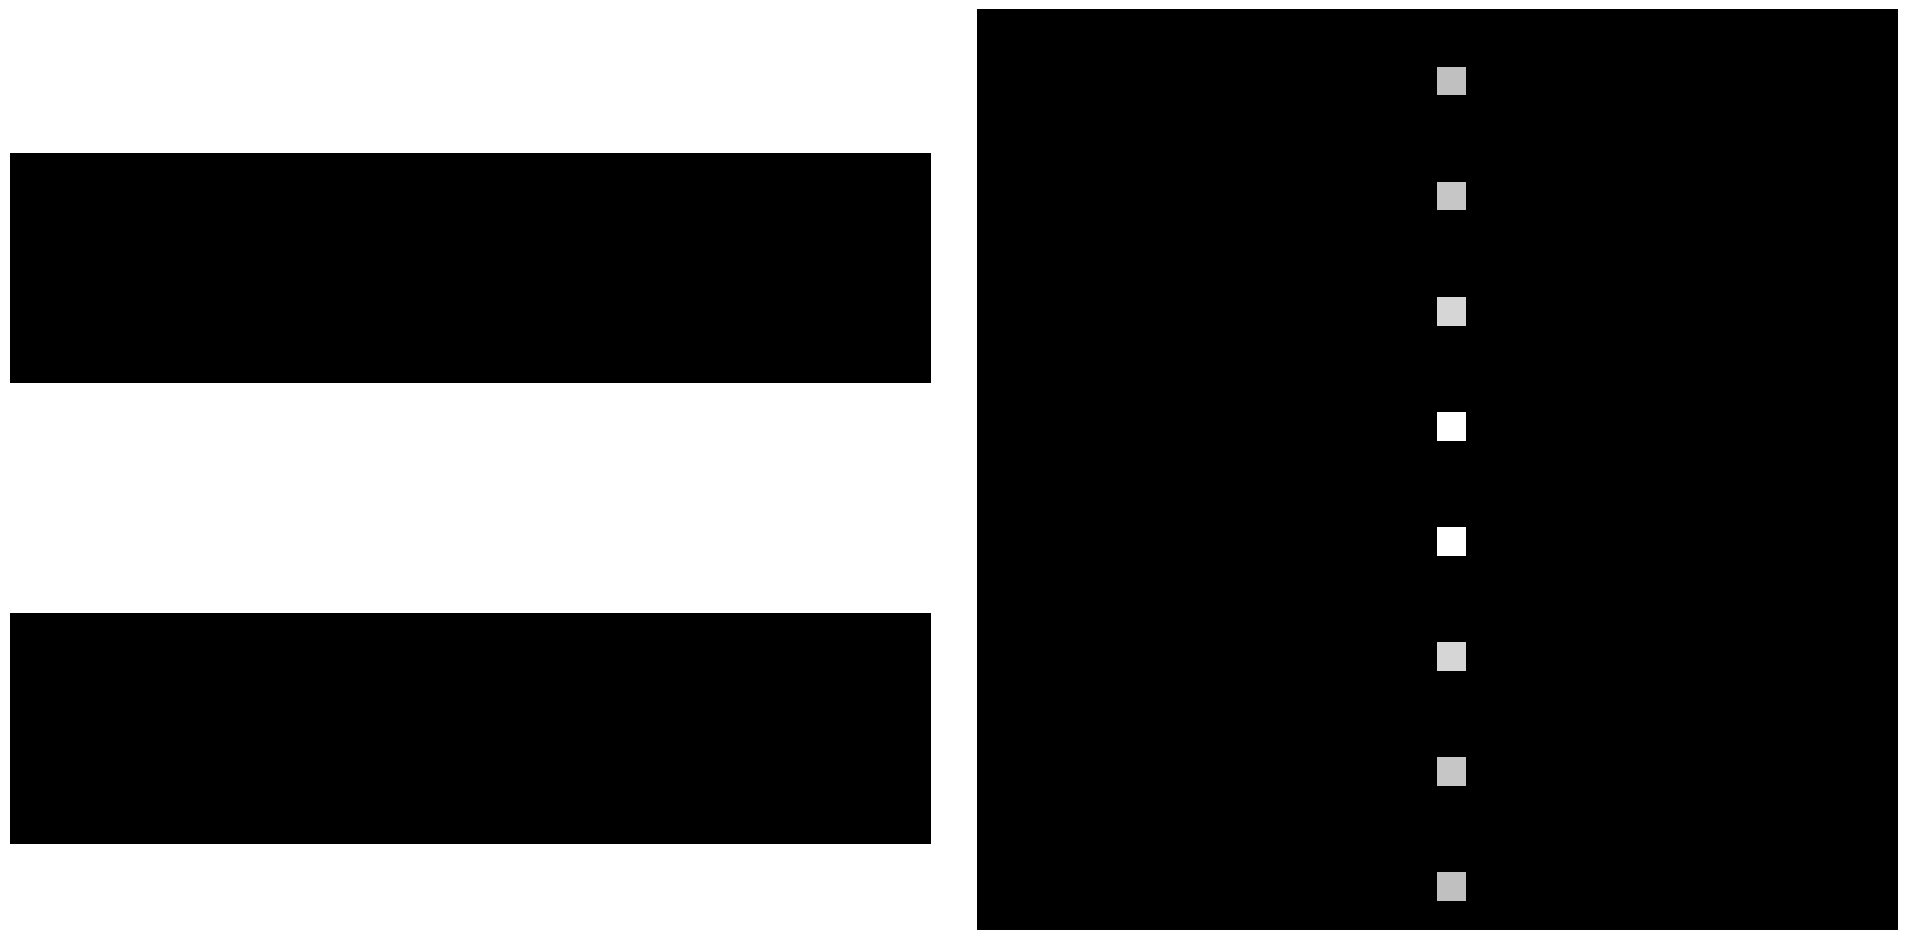

In [34]:
f = 2
image_D = np.sign(np.cos(2 * np.pi * f * m_grille / N))
fftD = np.fft.fft2(image_D)
module_D = np.fft.fftshift(np.abs(fftD))
display_images([image_D, np.log(1 + module_D)])

9.  Répéter les mêmes questions pour l'image $E$ définie par
    $$\large E_{m,n}=sign\left(\cos\left(\frac{2\pi(mf_1+nf_2)}{N}\right)\right)$$
    
avec $f_1=f_2=2$.

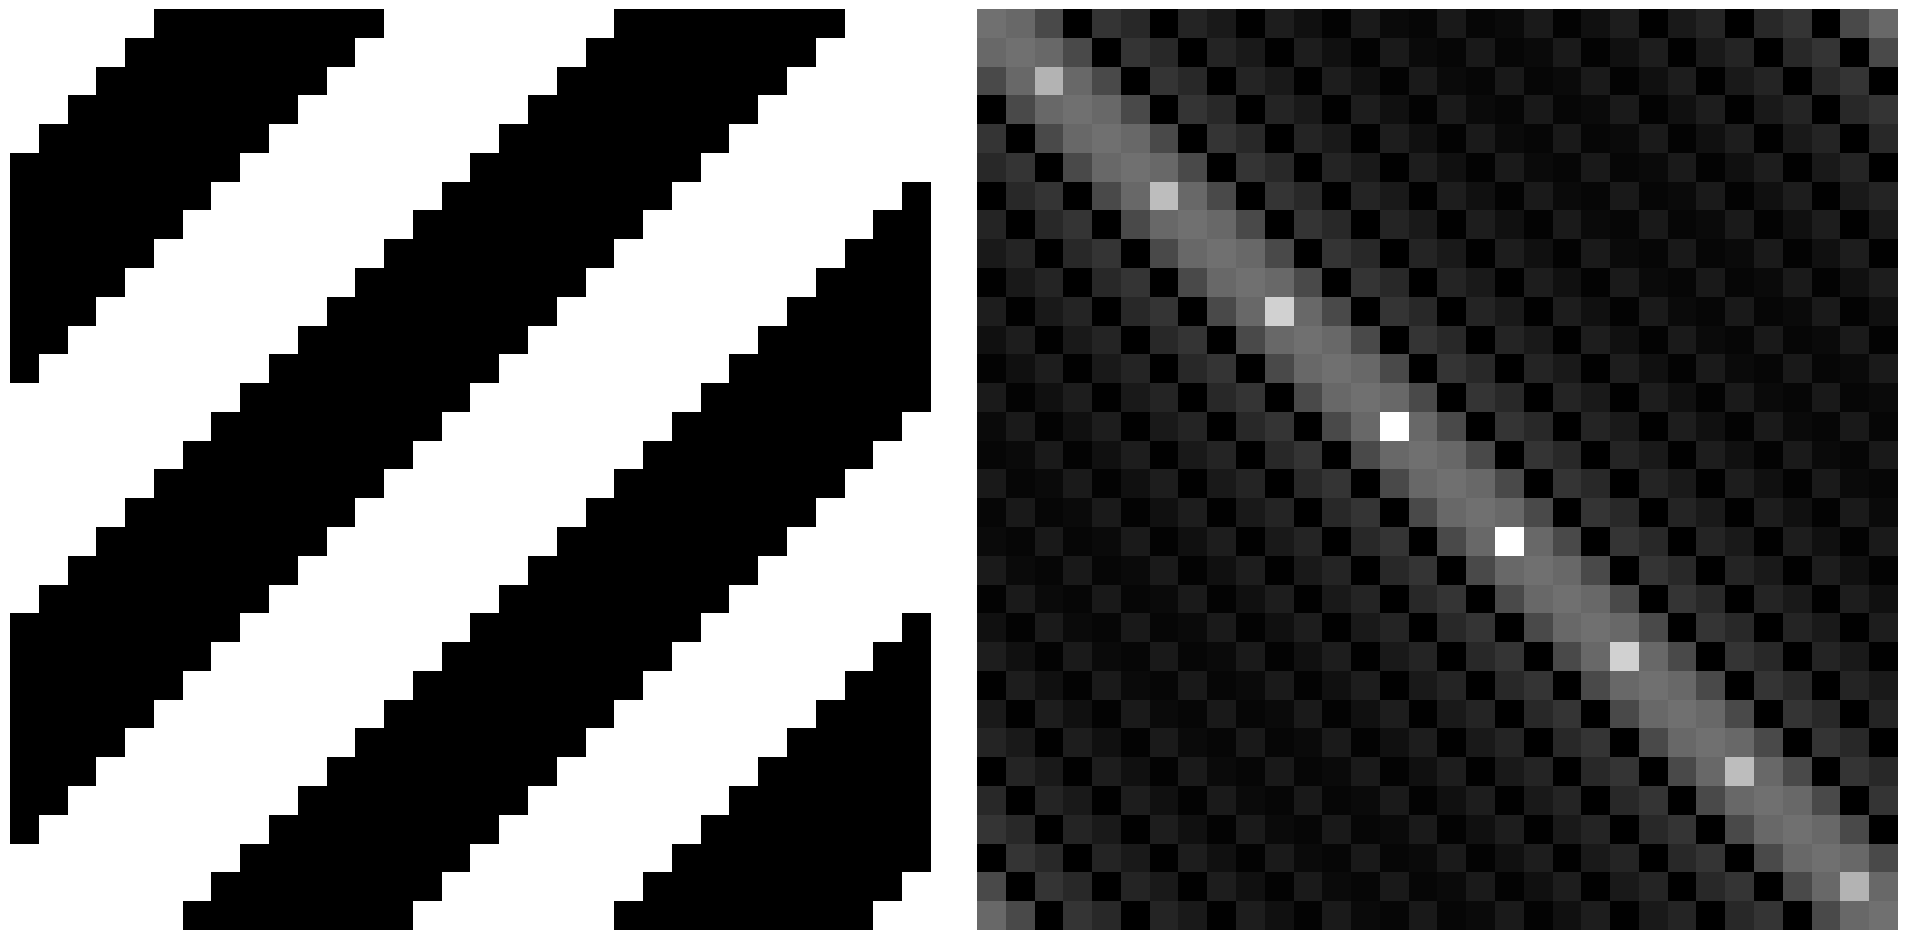

In [35]:
f1, f2 = 2, 2
image_E = np.sign(np.cos(2 * np.pi * (m_grille * f1 + n_grille * f2) / N))
fftE = np.fft.fft2(image_E)
module_E = np.fft.fftshift(np.abs(fftE))
display_images([image_E, np.log(1 + module_E)])

10.  Répéter les mêmes questions pour l'image $F$ définie par

$$\large F_{m,n}=\exp\left(-(m-5)^2-(n-10)^2\right)$$

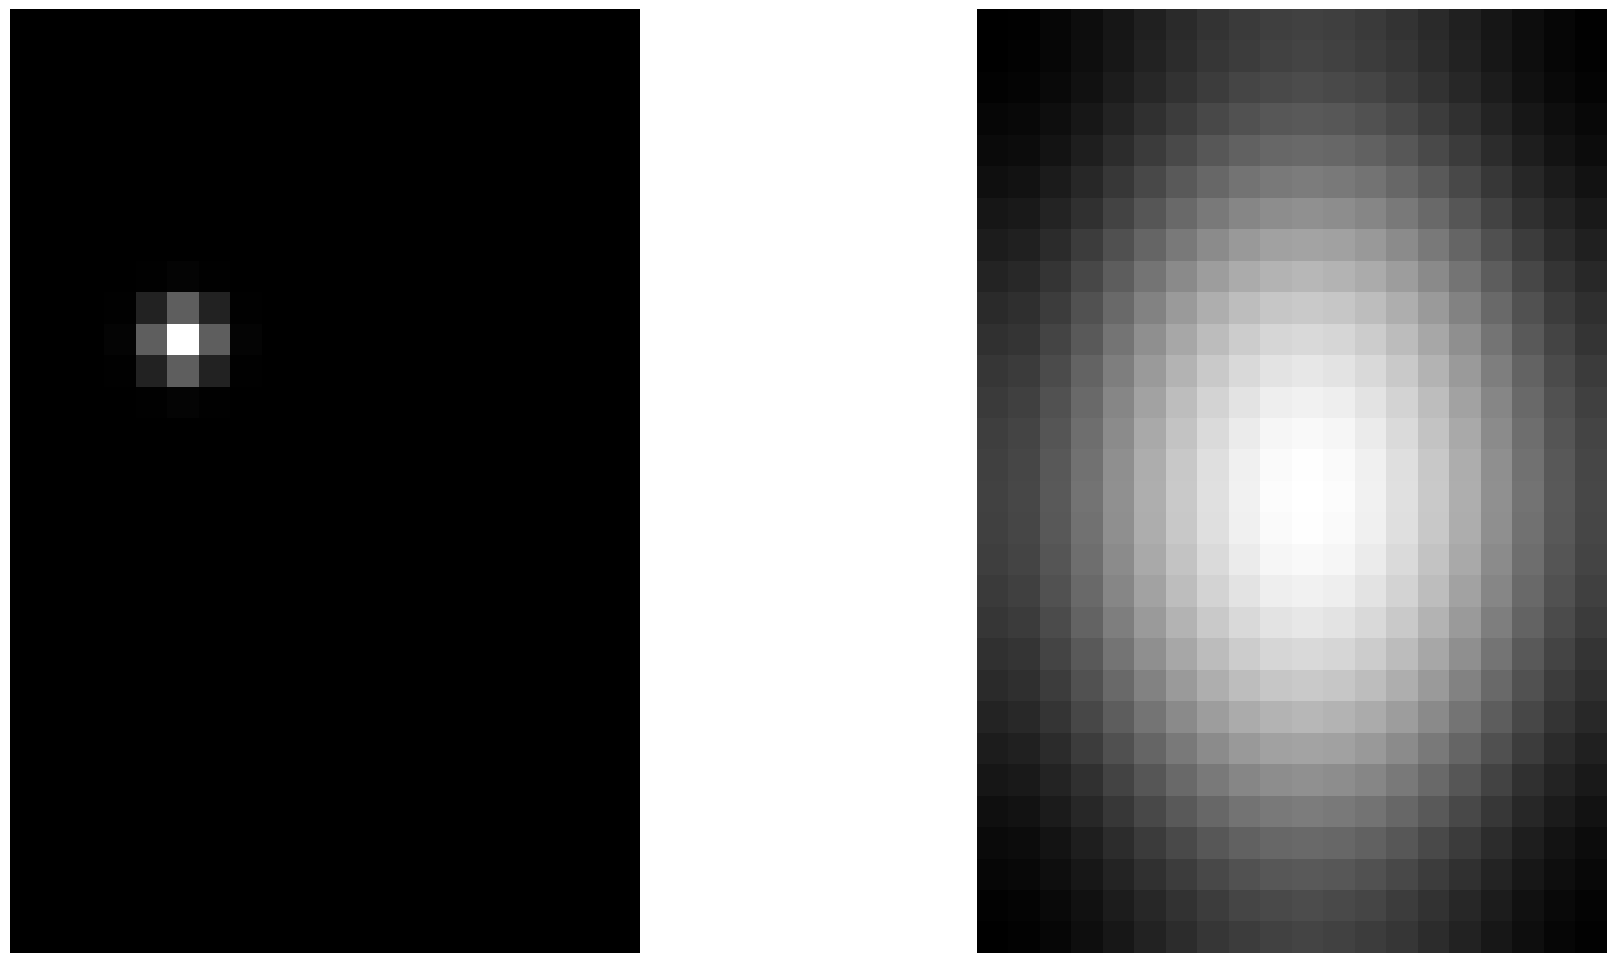

In [36]:
image_F = np.exp(-((m - 5)**2) -((n - 10)**2))
fftF = np.fft.fft2(image_F)
module_F = np.fft.fftshift(np.abs(fftF))
display_images([image_F, np.log(1 + module_F)])

## Exercice 6 – Modifier le module d'une FFT à deux dimensions

Le but de cet exercice est d'étudier l'effet d'une *troncature* de la transformée de Fourier. 

1.  Ouvrir l'image `barbara.png` et la stocker dans la variable `u`. Puis générer les cinq images $R_0$, $R_1$, $R_2$, $R_3$ et $R_4$ suivantes, de même taille que `barbara.png`:

    - $[R_0]_{m,n}=(m-256)^2+(n-256)^2$
    - $[R_1]_{m,n}=(m-183)^2+(n-318)^2$
    - $[R_2]_{m,n}=(m-338)^2+(n-192)^2$
    - $[R_3]_{m,n}=(m-205)^2+(n-211)^2$
    - $[R_4]_{m,n}=(m-305)^2+(n-311)^2$

In [37]:
u = open_image("barbara.png")
N = u.shape[0]

m, n = np.meshgrid(np.arange(N), np.arange(N))

R0 = (m - 256)**2 + (n - 256)**2
R1 = (m - 183)**2 + (n - 318)**2
R2 = (m - 338)**2 + (n - 192)**2
R3 = (m - 205)**2 + (n - 211)**2
R4 = (m - 305)**2 + (n - 311)**2


2.  Effectuer les opérations suivantes sur l'image $u$:

    - calculer sa fft,
    - la multiplier par 
    
        $$\large \text{fftshift}\left(\exp\left(-\frac{R_0}{200}\right)\right),$$
    
    - calculer la fft inverse,
    - représenter la partie réelle de l'image obtenue.

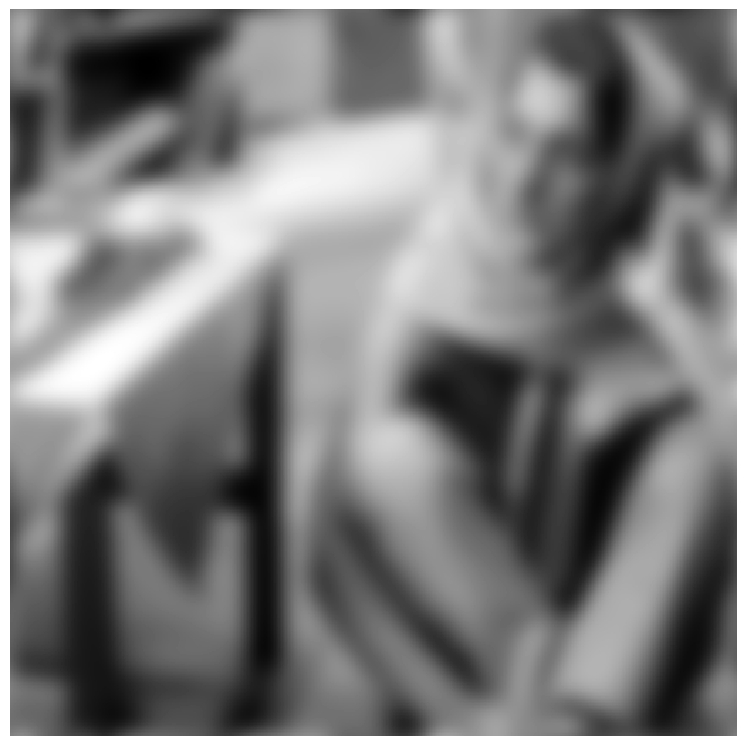

In [38]:
fftu = np.fft.fft2(u)
masque_1 = np.fft.fftshift(np.exp(-R0 / 200))

u_filtre_1_fft = fftu * masque_1
u_filtre_1 = np.real(np.fft.ifft2(u_filtre_1_fft))

display_image(u_filtre_1)

3.  Refaire la même chose, mais en multipliant cette fois par

    $$\large\text{fftshift}\left(\exp\left(-\frac{R_0}{200}\right)+\sum_{k=1}^4\exp\left(-\frac{R_k}{50}\right)\right)$$


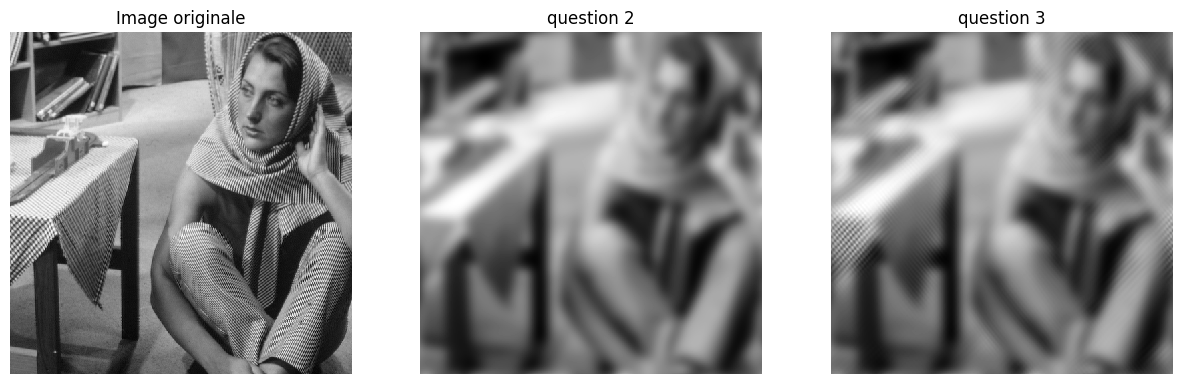

In [39]:
masque_2_brut = np.exp(-R0 / 200) + np.exp(-R1 / 50) + np.exp(-R2 / 50) + np.exp(-R3 / 50) + np.exp(-R4 / 50)
masque_2 = np.fft.fftshift(masque_2_brut)

u_filtre_2_fft = fftu * masque_2
u_filtre_2 = np.real(np.fft.ifft2(u_filtre_2_fft))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Image originale")
display_image(u)

plt.subplot(1, 3, 2)
plt.title("question 2")
display_image(u_filtre_1)

plt.subplot(1, 3, 3)
plt.title("question 3")
display_image(u_filtre_2)

4. Décrire qualitativement les résultats obtenus.

<div style=color:blue>
<u>Image filtrée avec R0 uniquement :</u>
L'image obtenue est extrêmement floue : on ne distingue plus que les formes globales (les grandes taches de lumière et d'ombre).
Le masque R0 agit comme un filtre passe-bas très sélectif. Il ne conserve que les très basses fréquences (autour du point central 256,256 dans le spectre). Toutes les hautes fréquences (les contours, les détails, les textures) ont été effacées (mises à zéro).
<br><br>
<u>Image filtrée par la question 3 :</u>
L'image reste globalement floue (car on a toujours le filtre basse fréquence R0), mais un détail très net réapparaît : les rayures du vêtement (pantalon/nappe) de Barbara, qui semblent s'étendre un peu partout sur l'image.
Explication : Les coordonnées des points R1, R2, R3, R4 ne sont pas choisies au hasard. Elles correspondent exactement à l'emplacement des pics d'énergie des hautes fréquences générés par les rayures du tissu dans le spectre de Fourier. En ajoutant ces "lucarnes" (filtres passe-bande), on laisse passer de manière très ciblée l'information qui code les rayures, tout en continuant de bloquer le reste des détails (bruit, peau, fond).
</div>